In [1]:
from ultralytics import YOLO
from PIL import Image
import numpy as np

model = YOLO('yolov8n-pose.pt')

# 키포인트 이름 정의
KEYPOINT_NAMES = [
    '코',                                    # 0
    '왼눈', '오른눈',                         # 1, 2
    '왼귀', '오른귀',                         # 3, 4
    '왼어깨', '오른어깨',                      # 5, 6
    '왼팔꿈치', '오른팔꿈치',                  # 7, 8
    '왼손목', '오른손목',                      # 9, 10
    '왼골반', '오른골반',                      # 11, 12
    '왼무릎', '오른무릎',                      # 13, 14
    '왼발목', '오른발목'                       # 15, 16
]

Results saved to C:\ai-starter\2026-10\10-13\runs\pose\predict


C:\Users\Admin\AppData\Roaming\Python\Python311\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 44060 (\N{HANGUL SYLLABLE GAE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Admin\AppData\Roaming\Python\Python311\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 53412 (\N{HANGUL SYLLABLE KI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Admin\AppData\Roaming\Python\Python311\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 54252 (\N{HANGUL SYLLABLE PO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Admin\AppData\Roaming\Python\Python311\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 51064 (\N{HANGUL SYLLABLE IN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Admin\AppData\Roaming\Python\Python311\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 53944 

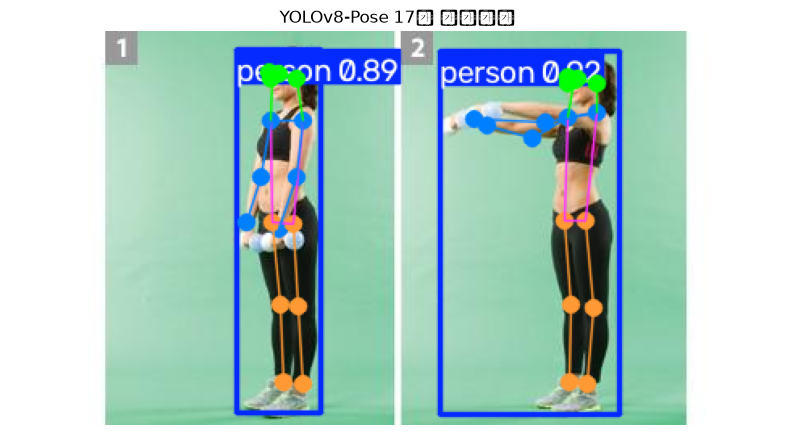


사람 1 키포인트 좌표 (x, y)
-----------------------------------
  [ 0] 코     : ( 345.6,   32.4)
  [ 1] 왼눈    : ( 351.0,   29.4)
  [ 2] 오른눈   : ( 345.4,   28.2)
  [ 3] 왼귀    : ( 363.4,   32.1)
  [ 4] 오른귀   : ( 349.3,   30.1)
  [ 5] 왼어깨   : ( 363.0,   50.5)
  [ 6] 오른어깨  : ( 345.6,   53.8)
  [ 7] 왼팔꿈치  : ( 331.3,   56.2)
  [ 8] 오른팔꿈치 : ( 323.9,   66.2)
  [ 9] 왼손목   : ( 287.8,   54.9)
  [10] 오른손목  : ( 295.9,   58.4)
  [11] 왼골반   : ( 356.9,  117.5)
  [12] 오른골반  : ( 343.2,  117.2)
  [13] 왼무릎   : ( 361.7,  171.2)
  [14] 오른무릎  : ( 347.7,  169.1)
  [15] 왼발목   : ( 357.4,  218.2)
  [16] 오른발목  : ( 347.0,  217.0)

사람 2 키포인트 좌표 (x, y)
-----------------------------------
  [ 0] 코     : ( 161.1,   29.8)
  [ 1] 왼눈    : ( 166.3,   26.5)
  [ 2] 오른눈   : ( 160.2,   25.6)
  [ 3] 왼귀    : ( 177.8,   29.6)
  [ 4] 오른귀   : ( 162.5,   27.7)
  [ 5] 왼어깨   : ( 181.6,   55.7)
  [ 6] 오른어깨  : ( 162.0,   55.2)
  [ 7] 왼팔꿈치  : ( 177.1,   90.1)
  [ 8] 오른팔꿈치 : ( 155.2,   90.1)
  [ 9] 왼손목   : ( 166.8,  122.1)
  [10] 오른손목  : ( 146.9

In [2]:
import requests
from PIL import Image
from io import BytesIO
import cv2
import matplotlib.pyplot as plt

# 인터넷 이미지 로드
url = 'https://m.health.chosun.com/site/data/img_dir/2013/06/26/2013062602051_5.jpg'
response = requests.get(url)
img = Image.open(BytesIO(response.content)).convert('RGB')

# 임시 저장 후 추론
img.save('test_pose.jpg')
results = model('test_pose.jpg', verbose=False, save=True)

# 키포인트 시각화
annotated = cv2.cvtColor(results[0].plot(), cv2.COLOR_BGR2RGB)
plt.figure(figsize=(10, 8))
plt.imshow(annotated)
plt.title('YOLOv8-Pose 17개 키포인트')
plt.axis('off')
plt.show()

# 키포인트 좌표 출력
if results[0].keypoints is not None:
    for person_idx, kpts in enumerate(results[0].keypoints.xy.cpu().numpy()):
        print(f'\n사람 {person_idx + 1} 키포인트 좌표 (x, y)')
        print('-' * 35)
        for i, (name, (x, y)) in enumerate(zip(KEYPOINT_NAMES, kpts)):
            print(f'  [{i:2d}] {name:<6}: ({x:6.1f}, {y:6.1f})')